In [1]:
# Day 4: Load Engineered Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/engineered_features.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (25249, 31)


,transaction_id,transaction_date,order_hour,region_id,region_name,product_id,product_name,category,customer_segment,units,...,avg_competitor_price,price_gap,price_gap_pct,discount_amount,revenue_per_unit,avg_competitor_price_missing,price_gap_missing,price_gap_pct_missing,discount_amount_missing,revenue_per_unit_missing
0,T00000001,2026-01-01,17,R01,North Metro,P001,Everyday Essentials,Essentials,Premium,1,...,37.31,-2.01,-5.387296,1.68,35.300000,0,0,0,0,0
1,T00000002,2026-01-01,8,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,3,...,37.31,0.41,1.098901,0.10,37.723333,0,0,0,0,0
2,T00000003,2026-01-01,15,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,2,...,37.31,-0.83,-2.224605,0.40,36.480000,0,0,0,0,0
3,T00000004,2026-01-01,14,R01,North Metro,P001,Everyday Essentials,Essentials,New,2,...,37.31,0.19,0.509247,-0.02,37.500000,0,0,0,0,0
4,T00000005,2026-01-01,10,R01,North Metro,P002,Home Care Pack,Home,Returning,1,...,59.23,-0.08,-0.135067,-0.14,59.150000,0,0,0,0,0


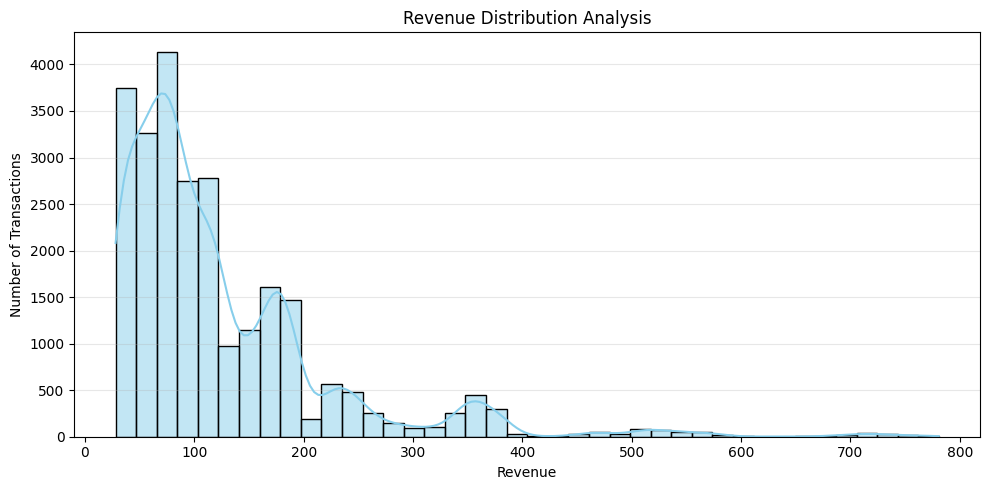

In [2]:
#Step 2 - Revenue Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="revenue",
    bins=40,
    kde=True,
    color="skyblue"
)

plt.title("Revenue Distribution Analysis")
plt.xlabel("Revenue")
plt.ylabel("Number of Transactions")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

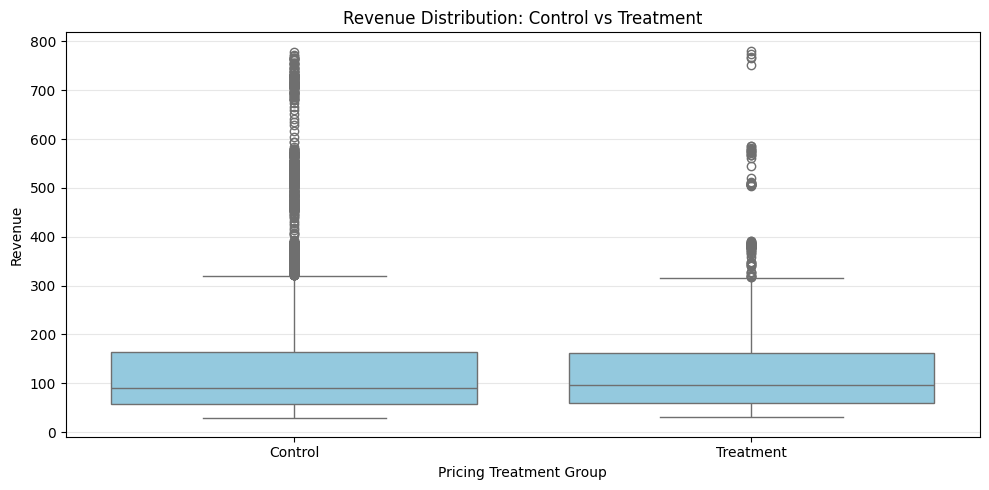

In [4]:
# Step 3: Revenue Distribution by Treatment Group

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="pricing_treatment_flag",
    y="revenue",
    color="skyblue"
)

plt.title("Revenue Distribution: Control vs Treatment")
plt.xlabel("Pricing Treatment Group")
plt.ylabel("Revenue")

plt.xticks([0, 1], ["Control", "Treatment"])

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

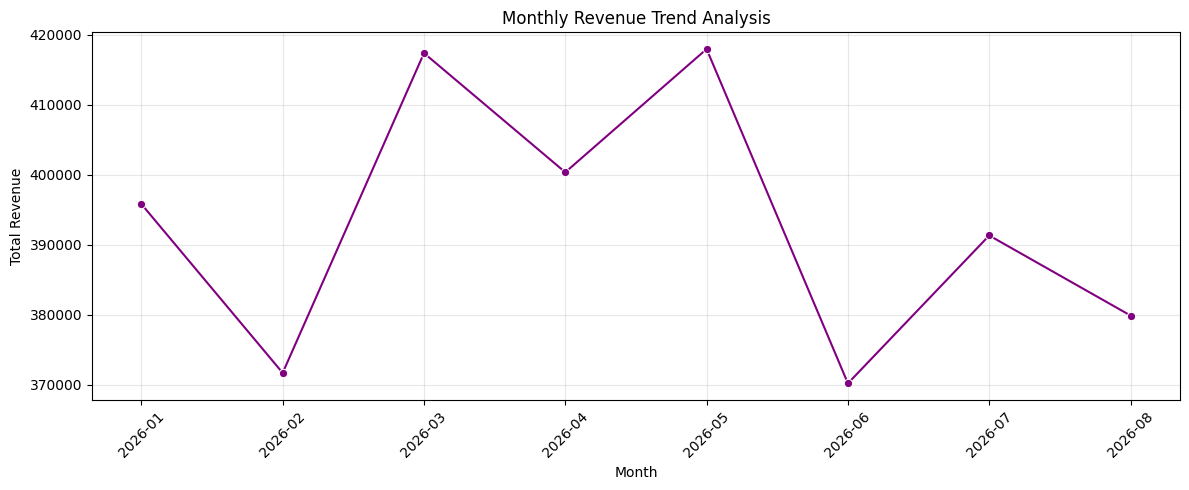

In [5]:
# Step 4: Monthly Revenue Trend Analysis

df["transaction_date"] = pd.to_datetime(df["transaction_date"])

df["month"] = df["transaction_date"].dt.to_period("M").astype(str)

monthly_revenue = (
    df.groupby("month")["revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="revenue",
    marker="o",
    color="purple"
)

plt.title("Monthly Revenue Trend Analysis")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

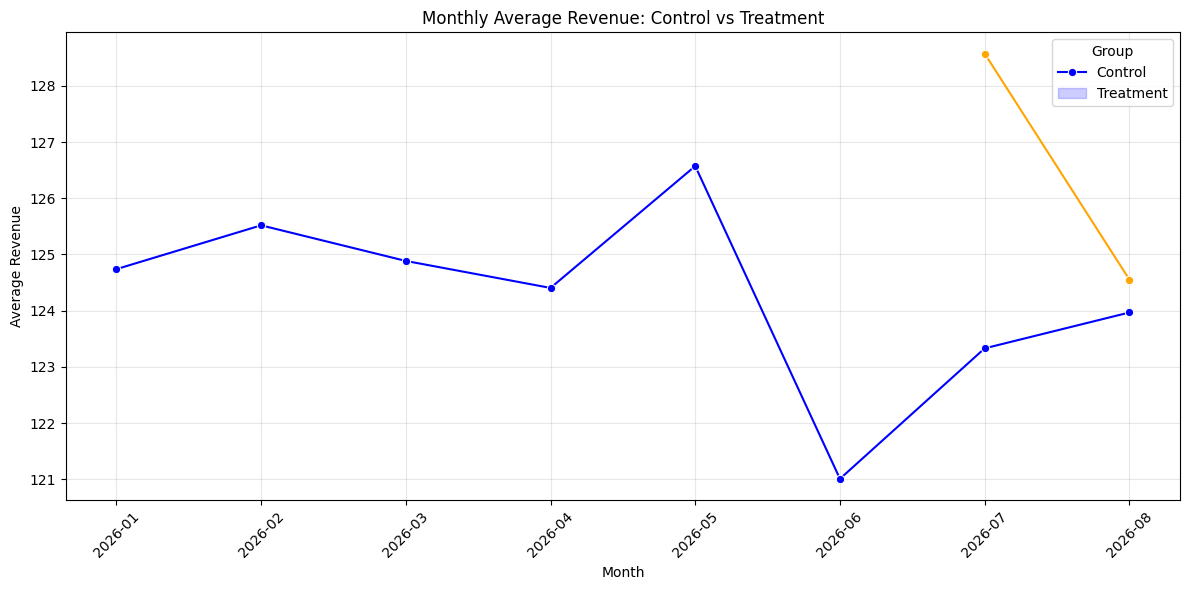

In [6]:
# Step 5: Monthly Revenue Comparison

monthly_comparison = (
    df.groupby(["month", "pricing_treatment_flag"])["revenue"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_comparison,
    x="month",
    y="revenue",
    hue="pricing_treatment_flag",
    marker="o",
    palette={0: "blue", 1: "orange"}
)

plt.title("Monthly Average Revenue: Control vs Treatment")
plt.xlabel("Month")
plt.ylabel("Average Revenue")

plt.xticks(rotation=45)
plt.legend(title="Group", labels=["Control", "Treatment"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

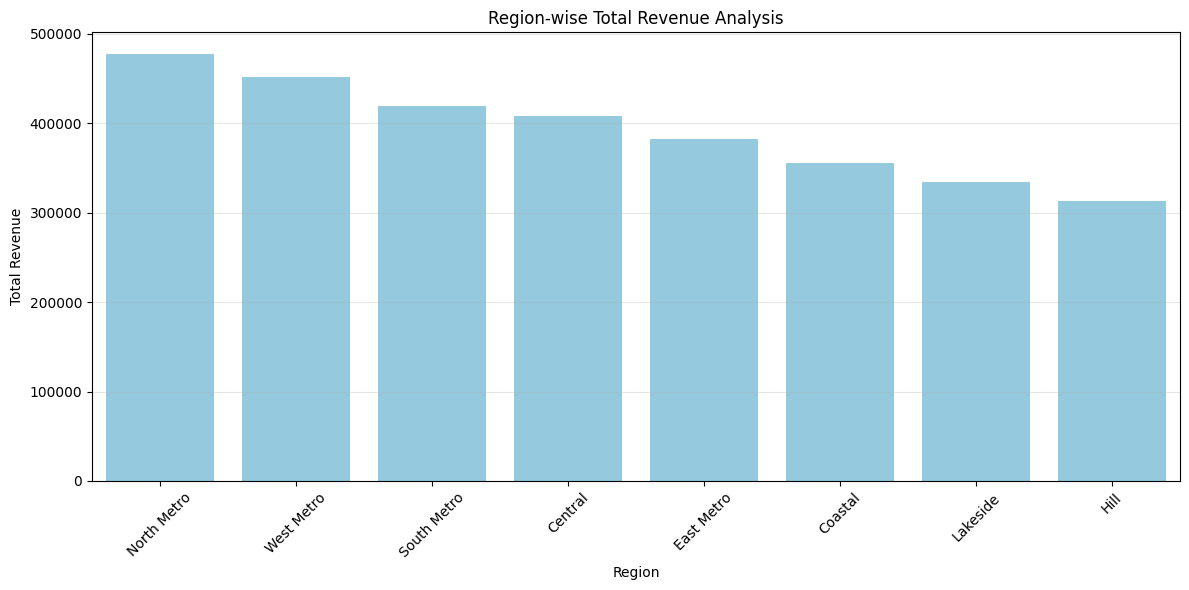

In [7]:
# Step 6: Region-wise Revenue Analysis

region_revenue = (
    df.groupby("region_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=region_revenue,
    x="region_name",
    y="revenue",
    color="skyblue"
)

plt.title("Region-wise Total Revenue Analysis")
plt.xlabel("Region")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

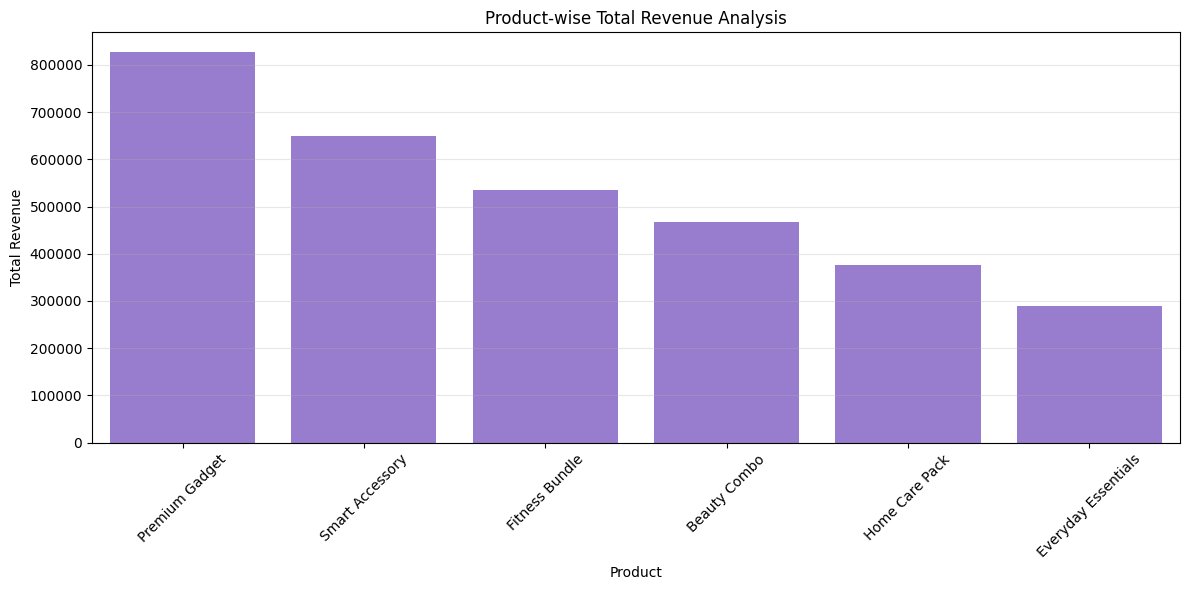

In [8]:
# Step 7: Product-wise Revenue Analysis

product_revenue = (
    df.groupby("product_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=product_revenue,
    x="product_name",
    y="revenue",
    color="mediumpurple"
)

plt.title("Product-wise Total Revenue Analysis")
plt.xlabel("Product")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

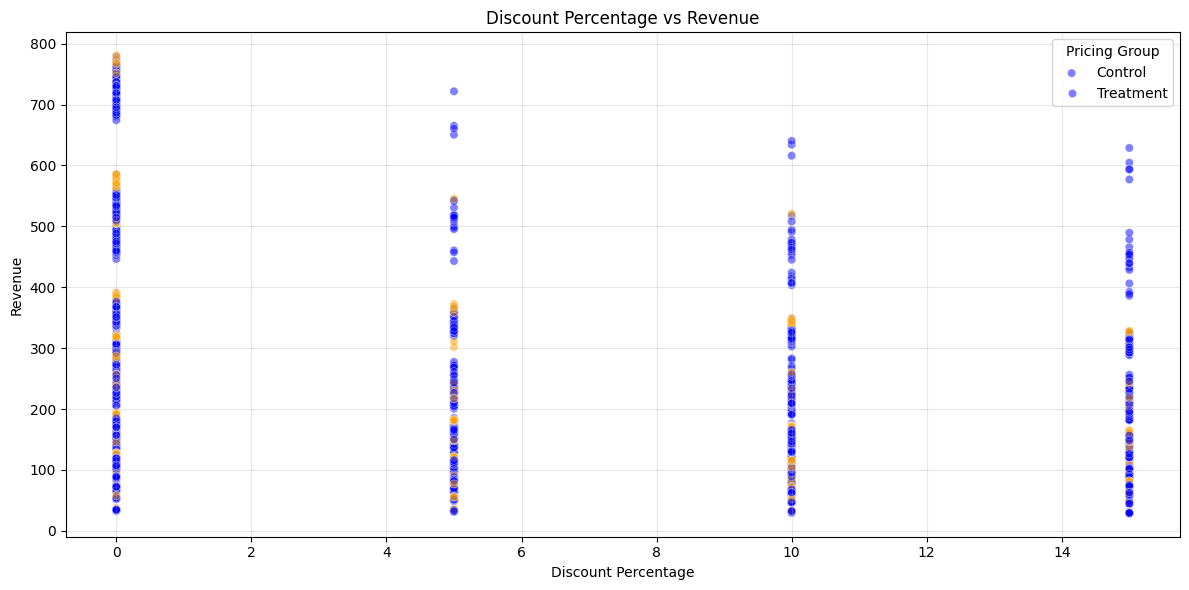

In [9]:
# Step 8: Discount vs Revenue Analysis

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="discount_pct",
    y="revenue",
    hue="pricing_treatment_flag",
    palette={0: "blue", 1: "orange"},
    alpha=0.5
)

plt.title("Discount Percentage vs Revenue")
plt.xlabel("Discount Percentage")
plt.ylabel("Revenue")

plt.legend(
    title="Pricing Group",
    labels=["Control", "Treatment"]
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

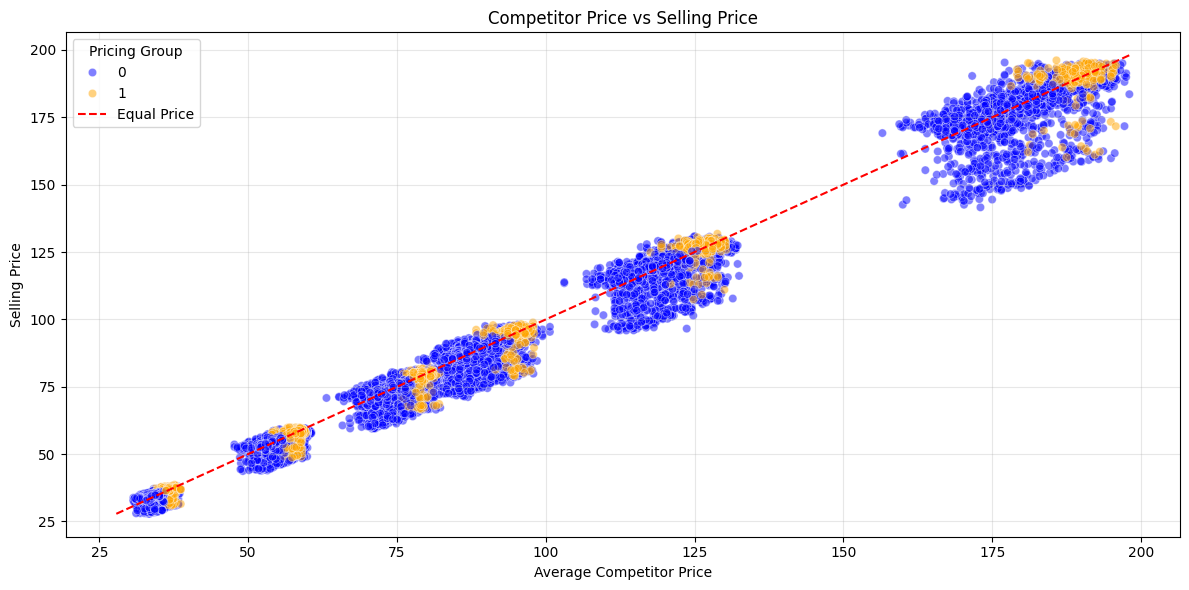

In [10]:
# Step 9: Competitor Price vs Selling Price Analysis

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="avg_competitor_price",
    y="selling_price",
    hue="pricing_treatment_flag",
    palette={0: "blue", 1: "orange"},
    alpha=0.5
)

# Equal-price reference line
price_min = min(
    df["avg_competitor_price"].min(),
    df["selling_price"].min()
)

price_max = max(
    df["avg_competitor_price"].max(),
    df["selling_price"].max()
)

plt.plot(
    [price_min, price_max],
    [price_min, price_max],
    color="red",
    linestyle="--",
    label="Equal Price"
)

plt.title("Competitor Price vs Selling Price")
plt.xlabel("Average Competitor Price")
plt.ylabel("Selling Price")

plt.legend(title="Pricing Group")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

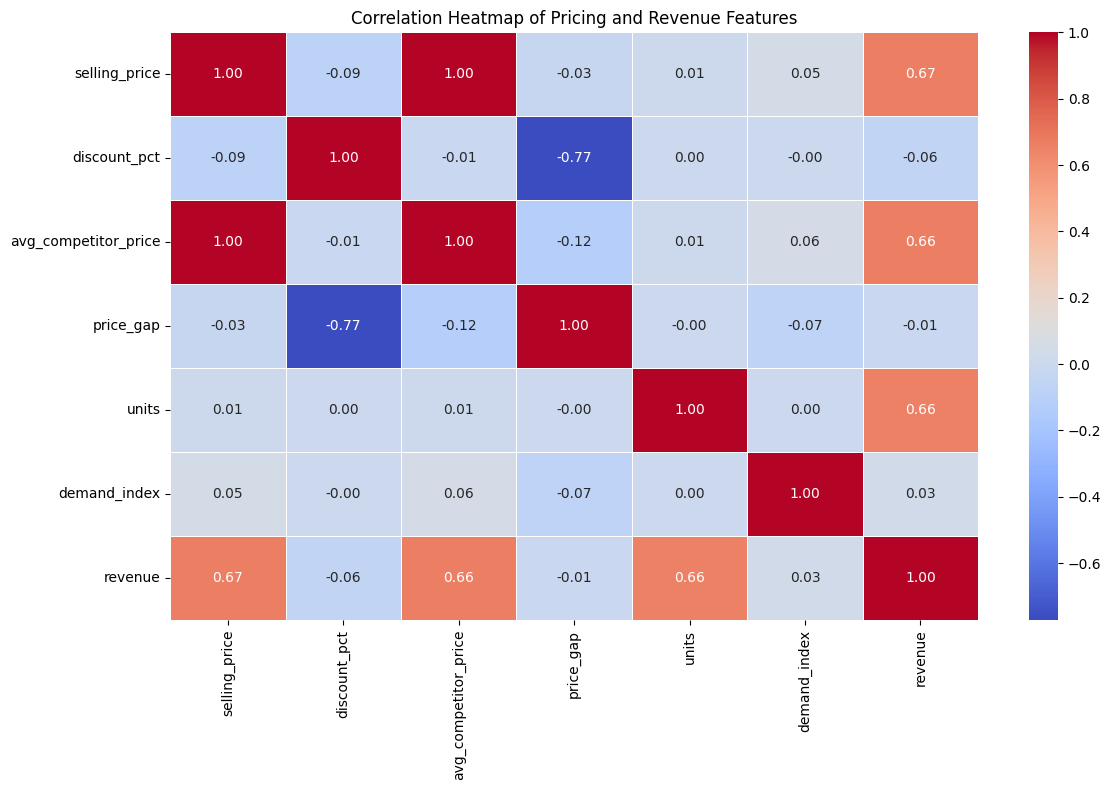

In [11]:
# Step 10: Correlation Heatmap Analysis

# Select numerical features
features = [
    "selling_price",
    "discount_pct",
    "avg_competitor_price",
    "price_gap",
    "units",
    "demand_index",
    "revenue"
]

# Calculate correlation matrix
correlation_matrix = df[features].corr()

# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Pricing and Revenue Features")

plt.tight_layout()
plt.show()

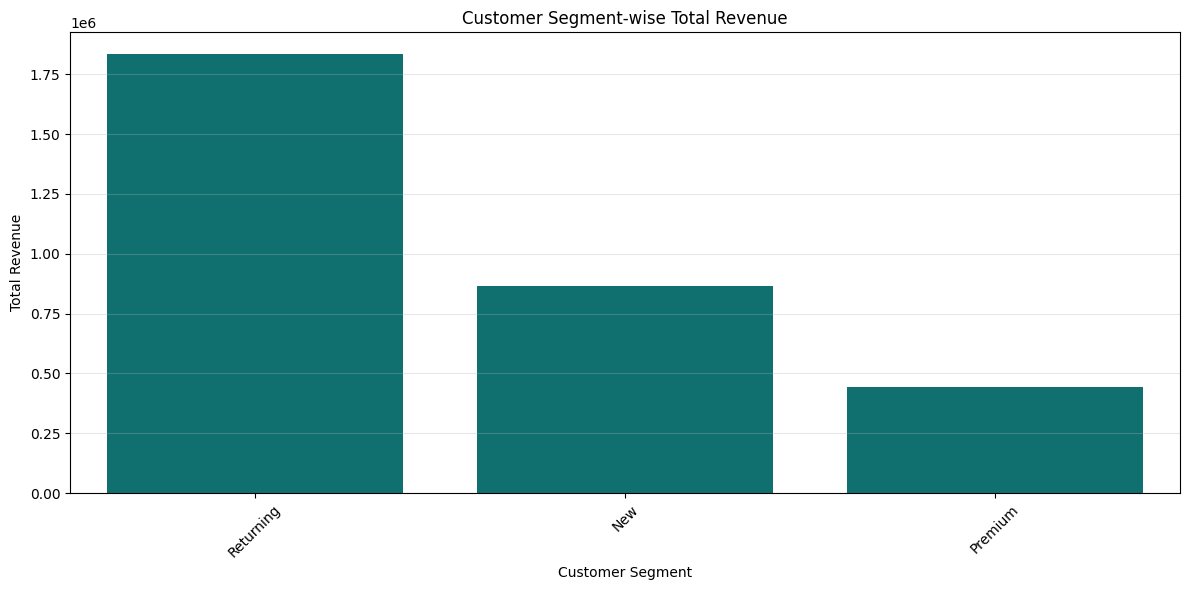

In [12]:
# Step 11: Customer Segment-wise Revenue Analysis

segment_revenue = (
    df.groupby("customer_segment")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_revenue,
    x="customer_segment",
    y="revenue",
    color="teal"
)

plt.title("Customer Segment-wise Total Revenue")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

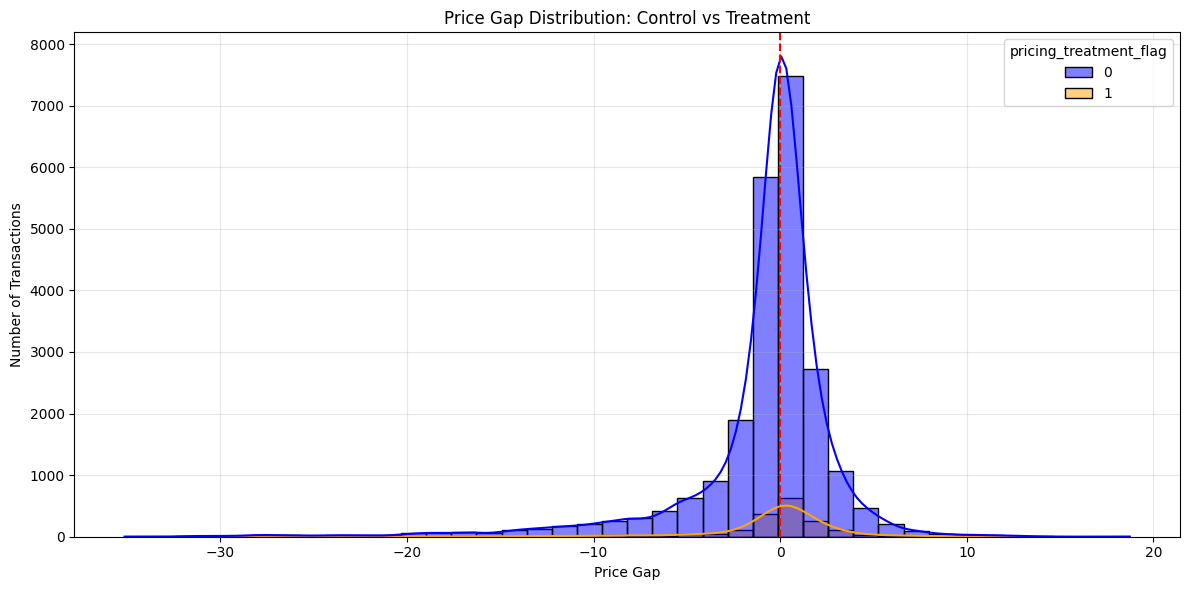

In [13]:
# Step 12: Price Gap Distribution Analysis

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="price_gap",
    hue="pricing_treatment_flag",
    bins=40,
    kde=True,
    palette={0: "blue", 1: "orange"},
    alpha=0.5
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Zero Price Gap"
)

plt.title("Price Gap Distribution: Control vs Treatment")
plt.xlabel("Price Gap")
plt.ylabel("Number of Transactions")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Step 13: Final Visualization Summary

print("=" * 55)
print("FINAL DATA VISUALIZATION SUMMARY")
print("=" * 55)

print("\n1. Dataset Overview")
print("Total Transactions:", len(df))
print("Total Features:", df.shape[1])

print("\n2. Regional Analysis")
print("Total Regions:", df["region_name"].nunique())
print("Highest Revenue Region:", region_revenue.iloc[0]["region_name"])

print("\n3. Product Analysis")
print("Total Products:", df["product_name"].nunique())
print("Highest Revenue Product:", product_revenue.iloc[0]["product_name"])

print("\n4. Customer Segment Analysis")
print("Total Customer Segments:", df["customer_segment"].nunique())
print("Highest Revenue Segment:", segment_revenue.iloc[0]["customer_segment"])

print("\n5. Pricing Treatment Distribution")
print(df["pricing_treatment_flag"].value_counts())

print("\n6. Revenue Summary")
print("Total Revenue:", round(df["revenue"].sum(), 2))
print("Average Revenue:", round(df["revenue"].mean(), 2))

print("\n7. Visualizations Completed")
print("Revenue Distribution")
print("Treatment vs Control Comparison")
print("Monthly Revenue Trends")
print("Regional Revenue Analysis")
print("Product Revenue Analysis")
print("Discount vs Revenue")
print("Competitor Price Comparison")
print("Correlation Heatmap")
print("Customer Segment Analysis")
print("Price Gap Distribution")

print("\nNote: Visualizations show descriptive patterns, not causal effects.")

print("\nFinal Visualization Summary Generated Successfully!")

FINAL DATA VISUALIZATION SUMMARY

1. Dataset Overview
Total Transactions: 25249
Total Features: 32

2. Regional Analysis
Total Regions: 8
Highest Revenue Region: North Metro

3. Product Analysis
Total Products: 6
Highest Revenue Product: Premium Gadget

4. Customer Segment Analysis
Total Customer Segments: 3
Highest Revenue Segment: Returning

5. Pricing Treatment Distribution
pricing_treatment_flag
0    23460
1     1789
Name: count, dtype: int64

6. Revenue Summary
Total Revenue: 3144424.75
Average Revenue: 124.54

7. Visualizations Completed
Revenue Distribution
Treatment vs Control Comparison
Monthly Revenue Trends
Regional Revenue Analysis
Product Revenue Analysis
Discount vs Revenue
Competitor Price Comparison
Correlation Heatmap
Customer Segment Analysis
Price Gap Distribution

Note: Visualizations show descriptive patterns, not causal effects.

Final Visualization Summary Generated Successfully!
